# 07. Mamba — 용담댐 시간 유입량 예측 (입력세트 A / B / C)

**모델**: Mamba (`model: mamba`) — 상태공간(SSM)
**한 줄 요약**: 선택적 상태공간모델(SSM). 입력에 따라 변하는 상태전이로 긴 시퀀스를 선형 시간에 처리.

이 노트북은 모델 비교 연구(10개 모델 × 3개 입력세트)의 **Mamba 부분**입니다. 모든 모델 노트북이 같은 구성을 가집니다.

1. 모델 설명 (논문 methodology용)
2. 자료와 실험 설정
3. 학습 (입력세트 A, B, C) 과 학습곡선
4. 학습 / 검증 / 테스트 기간 성능
5. 수문곡선 · 산점도 · 유량지속곡선
6. 홍수 첨두 재현
7. 결과 해석
8. 요약 (비교 노트북 `11_Comparison_Overall.ipynb`, `12_Comparison_Peaks.ipynb` 에서 사용하는 `results/mamba_<set>/` 생성)

**연구 설정 요약**

| 항목 | 내용 |
|---|---|
| 대상 | 용담댐 (유역면적 930.42 km²) 시간 유입량 (m³/s) |
| 기간 | 2006-01-01 ~ 2025-12-31 (20년, 175,320 시간) |
| 학습 / 검증 / 테스트 | 2006–2017 (12년) / 2018–2021 (4년) / 2022–2025 (4년) |
| 입력세트 A | 유역평균 강수량 `rf_avg` (1변수) |
| 입력세트 B | 관측소별 강수량 `rf_<관측소>` × 7 (7변수) |
| 입력세트 C | A + B (8변수) |
| 해상도 | 시간(hourly). MTS-LSTM만 일(daily) 강우를 추가로 사용 |
| 공통 학습 설정 | Adam, lr 1e-3, batch 256, MSE, seq_length 720 h, epoch 30–50 (early stopping patience 5), seed 111 |
| 평가 epoch | 검증 loss가 최소인 epoch (early stopping은 학습을 멈출 뿐 가중치를 되돌리지 않음) |
| 데이터셋 클래스 | `hourlycsv` (`data/YDDam_paper/`) — `prepare_data.py` 로 생성 |
| 설정 파일 | `configs/<model>_<set>.yml` — `make_configs.py` 로 생성 |
| 공통 코드 | `common.py` (run 관리·평가·그림), `model_docs.py` (모델 설명) |



## 1. 모델 설명 (Methodology)

**Mamba (Selective State Space Model; Gu & Dao, 2023; NeuralHydrology `mamba`)**

Mamba는 연속시간 **상태공간모델(SSM)** 을 이산화한 시퀀스 층이다. 은닉 상태 $s_t \in \mathbb{R}^{N}$(`d_state`=16)이 다음과 같이 갱신된다.

$$
s_t = \bar A_t s_{t-1} + \bar B_t x_t, \qquad y_t = C_t s_t, \qquad
\bar A_t = \exp(\Delta_t A),\; \bar B_t = \Delta_t B_t
$$

핵심은 **선택성(selectivity)**: $\Delta_t, B_t, C_t$ 가 입력 $x_t$ 의 함수여서, 모델이 "이 입력은 기억하고 저 입력은 흘려보낼지"를 시점마다
결정한다. $\Delta_t$ 가 크면 상태가 새 입력으로 빠르게 덮어써지고, 작으면 이전 상태가 오래 유지된다. 순환 계산이지만 병렬 스캔으로 구현되어
시퀀스 길이에 **선형** 비용이며, 앞단의 짧은 1-D 합성곱(`d_conv`=4)이 국소 패턴을 잡는다. NeuralHydrology 구현은 입력을 `hidden_size`(64)로
선형 변환한 뒤 Mamba 블록(`expand`=2 → 내부 폭 128) 하나와 head로 구성된다.

### 1.1 수문학적 관점에서의 특징

- 입력 의존적 시간 상수 $\Delta_t$ 는 수문학적으로 **강우가 있을 때는 빠르게, 없을 때는 느리게 반응하는 저류** 와 잘 맞는다. 즉 게이트
  없이도 LSTM의 망각 게이트와 비슷한 역할을 한다.
- 긴 창(720시간)을 트랜스포머보다 훨씬 적은 메모리로 처리하므로 **시간 해상도 장기 입력**에 실용적이다.
- 상대적으로 새로운 구조라 수문 분야 적용 사례가 적다. 본 비교에서 LSTM 대비 어떤 유량 구간에서 차이가 나는지가 관심사이다.

### 1.2 본 연구에서의 설정

| 항목 | 값 | 이유 |
|---|---|---|
| `hidden_size` (d_model) | 64 | 다른 모델과 동일 |
| `d_state` / `d_conv` / `expand` | 16 / 4 / 2 | mamba_ssm 기본값 |
| `output_dropout` | 0.4 | 동일 |

### 참고문헌

- Gu, A., & Dao, T. (2023). Mamba: Linear-time sequence modeling with selective state spaces. *arXiv:2312.00752*.


## 2. 자료와 실험 설정

`common.py` 가 run 디렉터리 탐색, 평가, 그림을 모두 담당하므로 노트북 코드는 짧습니다. 아래 셀은 공통 설정을 불러오고 그림 스타일(큰 글꼴,
300 dpi 저장)을 지정합니다.

In [1]:
%matplotlib inline
import sys, warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
import common
from common import SETS, MODEL_NAME, MODEL_COLOR, SET_COLOR, SET_STYLE, PERIODS, PERIOD_LABEL
from model_docs import MODEL_DOCS, MODEL_FAMILY

warnings.filterwarnings("ignore", category=FutureWarning)
common.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

MODEL = "mamba"
NAME = MODEL_NAME[MODEL]
print(NAME, "->", common.MODEL_SPECS[MODEL]["nh_model"])

Mamba -> mamba


### 2.1 자료 개요

연도별 유역평균 강수량과 유입량(평균·최대)입니다. 음영은 학습(회색) / 검증(주황) / 테스트(녹색) 기간입니다.
테스트 기간(2022–2025)에는 2023년과 2024년의 큰 홍수가 포함되어 있고, 학습 기간에는 2020년(최대 4,395 m³/s)이 **포함되지 않는다**는 점에 유의합니다
(2020년은 검증 기간). 즉 모델은 학습에서 본 적 없는 크기의 홍수를 검증·테스트에서 재현해야 하며, 이것이 모델 간 외삽 능력 차이를 드러냅니다.

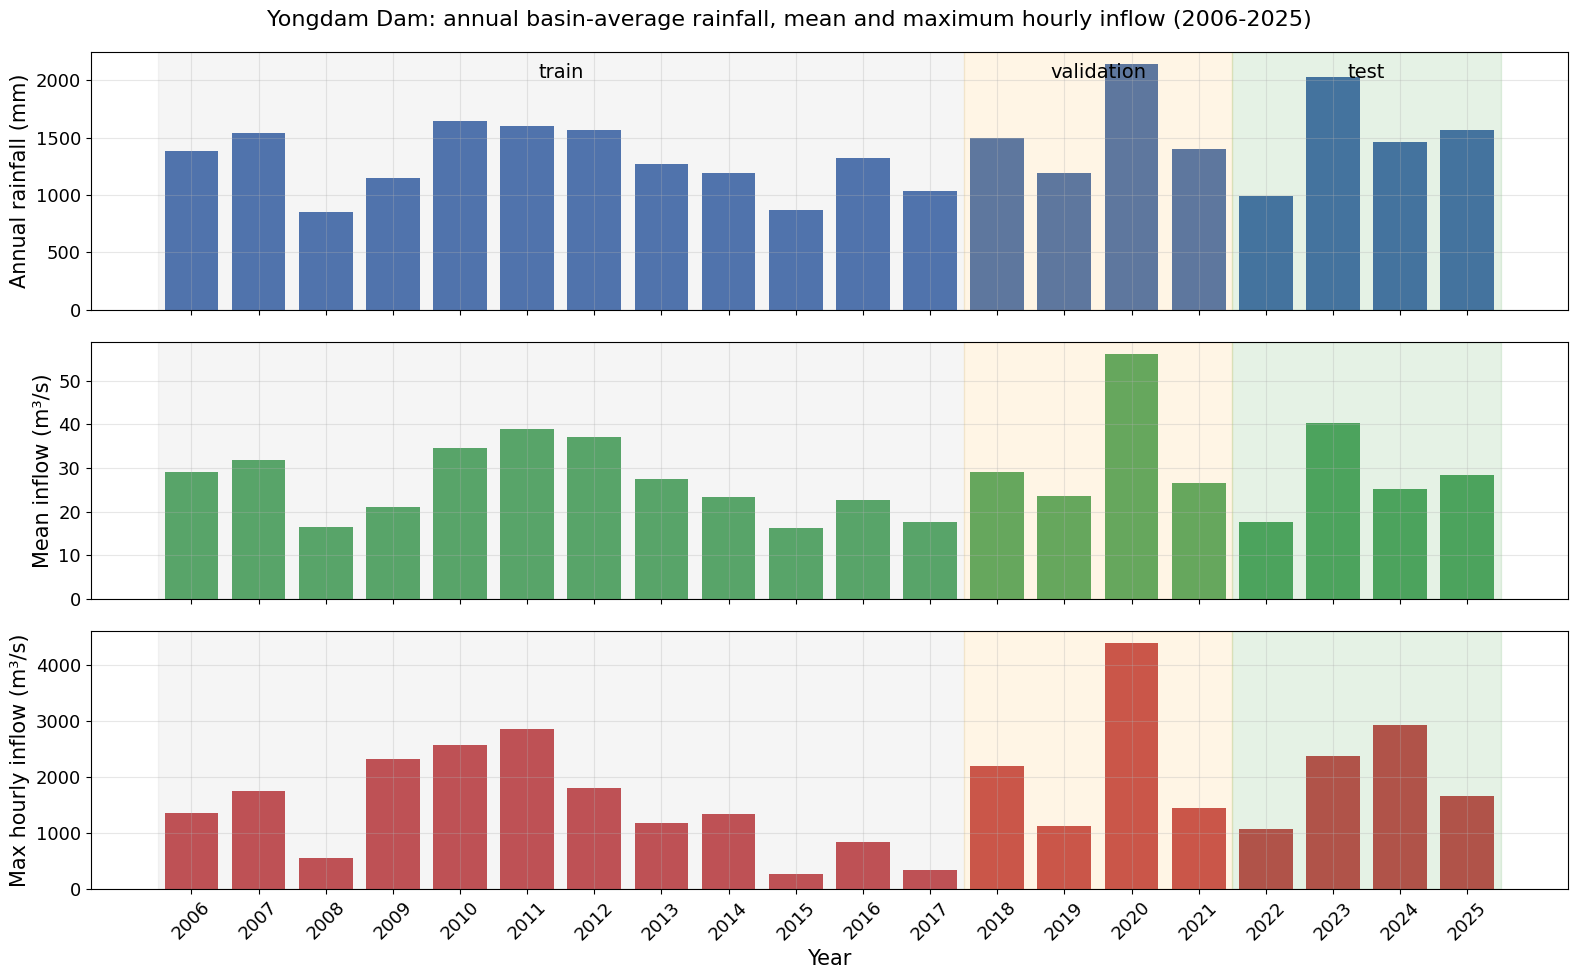

In [2]:
rain = common.load_rainfall(["rf_avg"])["rf_avg"]
inflow = common.load_observed_inflow()
annual = pd.DataFrame({"rain_mm": rain.resample("YE").sum(), "inflow_mean": inflow.resample("YE").mean(),
                       "inflow_max": inflow.resample("YE").max()})
annual.index = annual.index.year
annual = annual.loc[2006:2025]

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
axes[0].bar(annual.index, annual["rain_mm"], color="#4c72b0")
axes[0].set_ylabel("Annual rainfall (mm)")
axes[1].bar(annual.index, annual["inflow_mean"], color="#55a868")
axes[1].set_ylabel("Mean inflow (m³/s)")
axes[2].bar(annual.index, annual["inflow_max"], color="#c44e52")
axes[2].set_ylabel("Max hourly inflow (m³/s)")
for ax in axes:
    ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
    ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
    ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
axes[0].text(2011.5, axes[0].get_ylim()[1] * 0.9, "train", ha="center", fontsize=14)
axes[0].text(2019.5, axes[0].get_ylim()[1] * 0.9, "validation", ha="center", fontsize=14)
axes[0].text(2023.5, axes[0].get_ylim()[1] * 0.9, "test", ha="center", fontsize=14)
axes[2].set_xlabel("Year")
axes[2].set_xticks(annual.index)
axes[2].tick_params(axis="x", rotation=45)
fig.suptitle("Yongdam Dam: annual basin-average rainfall, mean and maximum hourly inflow (2006-2025)", fontsize=16)
fig.tight_layout()
plt.show()


### 2.2 입력세트별 설정 파일

세 입력세트의 설정은 `dynamic_inputs` (와 모델에 따라 그에 연동된 몇 개 키)만 다릅니다. 아래 표는 공통 설정과 다른 항목만 보여 줍니다.
전체 파일은 `configs/mamba_<set>.yml` 입니다.

In [3]:
rows = {}
for s in SETS:
    rows[f"Set {s}"] = {k: str(v) for k, v in common.model_specific_config(MODEL, s).items()}
cfg_table = pd.DataFrame(rows).fillna("")
display(cfg_table)
print(Path(common.config_path(MODEL, "A")).read_text())

,Set A,Set B,Set C
experiment_name,mamba_A,mamba_B,mamba_C
model,mamba,mamba,mamba
hidden_size,64,64,64
mamba_d_state,16,16,16
mamba_d_conv,4,4,4
mamba_expand,2,2,2
output_dropout,0.4,0.4,0.4
dynamic_inputs,['rf_avg'],"['rf_9000028', 'rf_9000027', 'rf_9000023', 'rf...","['rf_avg', 'rf_9000028', 'rf_9000027', 'rf_900..."


experiment_name: mamba_A
run_dir: null
train_basin_file: YDDam_basin.txt
validation_basin_file: YDDam_basin.txt
test_basin_file: YDDam_basin.txt
train_start_date: 01/01/2006
train_end_date: 31/12/2017
validation_start_date: 01/01/2018
validation_end_date: 31/12/2021
test_start_date: 01/01/2022
test_end_date: 31/12/2025
seed: 111
device: cuda:0
validate_every: 1
validate_n_random_basins: 1
metrics:
- NSE
- KGE
head: regression
output_activation: linear
optimizer: Adam
loss: MSE
learning_rate:
  0: 0.001
batch_size: 256
epochs: 50
clip_gradient_norm: 1
early_stopping: true
patience_early_stopping: 5
minimum_epochs_before_early_stopping: 30
patience_dynamic_learning_rate: 3
factor_dynamic_learning_rate: 0.5
seq_length: 720
predict_last_n: 1
num_workers: 4
log_interval: 100
log_tensorboard: false
log_n_figures: 0
save_weights_every: 1
save_validation_results: false
dataset: hourlycsv
data_dir: ../../data/YDDam_paper
forcings:
- hourly
target_variables:
- inflow
clip_targets_to_zero:
- infl

## 3. 학습

`common.train()` 은 완료된 run (`runs/mamba_<set>_<날짜>_<시각>/`) 이 있으면 학습을 건너뛰고, 없으면 `nh-run train` 을 서브프로세스로
실행합니다 (`train_all.py` 로 미리 학습해 두어도 같은 run 을 사용합니다). 이어서 `common.evaluate_run()` 이

1. `output.log` 에서 epoch별 학습/검증 loss 와 검증 NSE/KGE 를 읽고,
2. 검증 loss 최소 epoch 을 골라 학습·검증·테스트 기간을 평가(`nh-run evaluate`)하고,
3. 시간 단위 예측을 m³/s 로 통일해 지표를 계산한 뒤 `results/mamba_<set>/` 에 저장합니다.

In [4]:
summaries, histories, preds = {}, {}, {}
for s in SETS:
    run_dir = common.train(MODEL, s, in_process=False)
    summaries[s] = common.evaluate_run(MODEL, s, run_dir)
    histories[s] = common.load_saved_history(MODEL, s)
    preds[s] = common.load_saved_predictions(MODEL, s)
    print(f"Set {s}: run={summaries[s]['run_dir']}  epochs={summaries[s]['epochs_trained']}  best={summaries[s]['best_epoch']}  "
          f"params={summaries[s]['n_parameters']:,}  {summaries[s]['epoch_time_mean_s']:.0f} s/epoch")

[mamba_A] completed run found, skipping training: mamba_A_2110_012304
Set A: run=mamba_A_2110_012304  epochs=36  best=24  params=32,833  34 s/epoch
[mamba_B] completed run found, skipping training: mamba_B_2110_012304
Set B: run=mamba_B_2110_012304  epochs=45  best=1  params=33,217  33 s/epoch
[mamba_C] completed run found, skipping training: mamba_C_2110_012304


Set C: run=mamba_C_2110_012304  epochs=38  best=4  params=33,281  36 s/epoch


### 3.1 학습곡선

왼쪽: 학습 loss(표준화된 MSE), 가운데: 검증 loss, 오른쪽: 검증 기간(2018–2021) NSE. 점선은 검증 loss 최소 epoch(평가에 쓴 체크포인트)입니다.
early stopping 은 30 epoch 이후 검증 loss 가 5 epoch 연속 개선되지 않으면 학습을 멈춥니다.

- 학습 loss 가 계속 내려가는데 검증 loss 가 올라가면 **과적합**, 둘 다 높은 채 머물면 **표현력 부족 또는 학습률 문제**입니다.
- 검증 NSE 가 들쭉날쭉하면 2020년 대홍수(검증 기간) 재현이 epoch 마다 흔들린다는 뜻입니다.

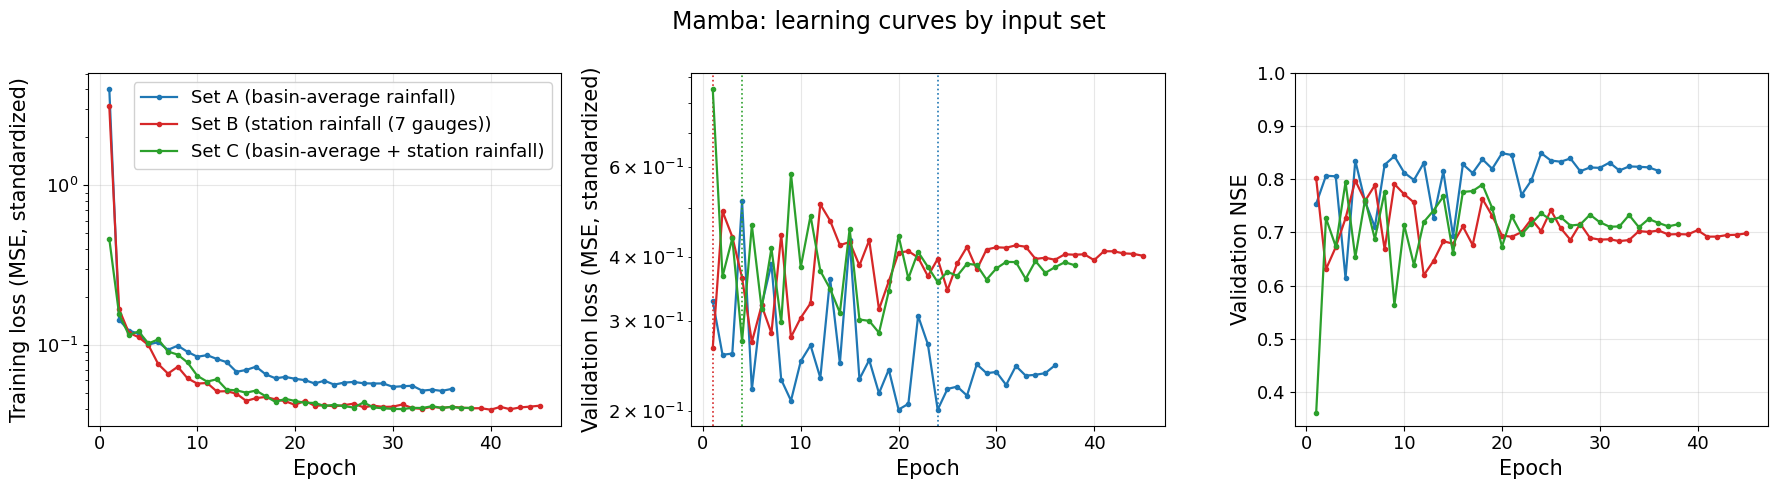

In [5]:
fig = common.plot_learning_curves(histories, title=f"{NAME}: learning curves by input set",
                                  labels={s: f"Set {s} ({common.INPUT_SET_NAMES[s]})" for s in SETS},
                                  colors=SET_COLOR, styles={s: "-" for s in SETS},
                                  best_epochs={s: summaries[s]["best_epoch"] for s in SETS})
common.save_fig(fig, f"{MODEL}_learning_curves")
plt.show()

## 4. 학습 / 검증 / 테스트 기간 성능

모든 지표는 **시간 단위, m³/s** 로 계산합니다 (MC-LSTM 의 mm/h 예측도 변환). 지표의 의미:

| 지표 | 의미 | 이상값 |
|---|---|---|
| NSE | 관측 평균 대비 설명력. 제곱오차 기반이라 **홍수(고유량)** 에 민감 | 1 |
| KGE | 상관(r)·변동성비(α)·편향비(β)를 함께 보는 지표 | 1 |
| RMSE / MAE | 오차의 크기 (m³/s) | 0 |
| PBIAS | 총량 편향(%) (+ 과대, − 과소) | 0 |
| Alpha-NSE / Beta-NSE | 표준편차 비 / 평균 편향(관측 표준편차로 정규화) | 1 / 0 |
| FHV / FMS / FLV | 유량지속곡선의 고유량(상위 2%) / 중간 구간 기울기 / 저유량(하위 30%) 편향(%) | 0 |
| Peak-Timing | 관측 첨두(자동 탐지)의 시각 오차 평균(h) | 0 |
| Peak-MAPE | 자동 탐지된 모든 첨두의 평균 절대 백분율 오차(%) | 0 |
| Missed-Peaks | 자동 탐지 첨두 중 예측이 놓친 비율 | 0 |

(첨두 자동 탐지는 라이브러리 기본 규칙으로 작은 첨두까지 포함하므로 값이 큽니다. 큰 홍수사건에 대한 분석은 6절과 `" + NB_PEAKS + "` 참고.)

In [6]:
rows = []
for s in SETS:
    for p in PERIODS:
        rows.append({"set": s, "period": p, **summaries[s]["metrics"][p]})
metrics_long = pd.DataFrame(rows).set_index(["set", "period"])[common.MAIN_METRICS]
display(metrics_long.round(3))
metrics_long.to_csv(common.RESULTS_DIR / f"{MODEL}_metrics_by_period.csv")

NSE    KGE    RMSE     MAE   PBIAS  Pearson-r  Alpha-NSE  Beta-NSE     FHV     FMS      FLV  Peak-Timing  Peak-MAPE  Missed-Peaks
set period                                                                                                                                         
A   train       0.897  0.875  23.126  11.481  -0.612      0.949      0.887    -0.002 -10.532 -49.459 -132.045        5.577     61.494         0.660
    validation  0.849  0.920  45.426  14.794   0.194      0.923      0.977     0.001  -4.999 -25.850  -69.044        2.585     52.827         0.699
    test        0.843  0.834  34.380  13.729  14.697      0.922      0.996     0.047   3.848 -60.554 -184.721        1.904     43.841         0.680
B   train       0.737  0.705  37.125  13.581  -2.803      0.868      0.737    -0.010 -21.850 -35.032 -127.337        6.262     66.363         0.673
    validation  0.802  0.769  52.130  16.275  -5.486      0.901      0.798    -0.016 -19.037 -21.275  -66.844        5.122     63.867         0.712
    test        0.740  0.723  44.152  15.559   7.963      0.866      0.771     0.026 -16.491 -55.991 -180.252        2.327     45.656         0.684
C   train       0.834  0.823  29.465  12.749   1.029      0.916      0.844     0.004 -12.473  -6.943 -128.112        6.100     60.490         0.715
    validation  0.795  0.896  53.016  15.769   0.483      0.901      1.029     0.001  -4.996   8.406  -67.281        3.610     52.191         0.741
    test        0.828  0.798  35.894  14.066  11.984      0.912      0.863     0.039  -7.900 -39.232 -180.779        1.962     41.410         0.740

### 4.1 기간별 NSE · KGE · PBIAS 비교

학습 기간 대비 검증·테스트 기간의 하락 폭이 **일반화 성능**을 보여 줍니다. 입력세트 간 차이는 관측소별 강우(B, C)가 유역평균(A)보다
추가 정보를 주는지를 말해 줍니다.

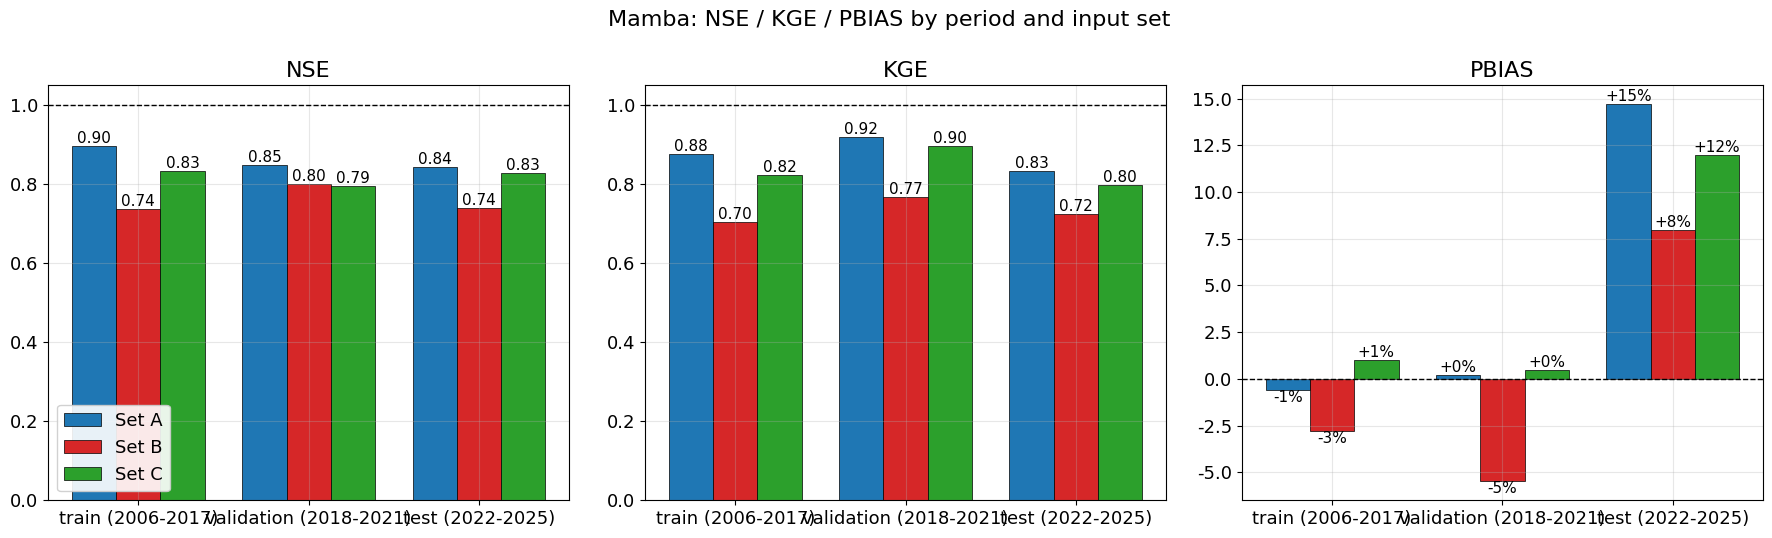

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, metric in zip(axes, ["NSE", "KGE", "PBIAS"]):
    x = np.arange(len(PERIODS))
    w = 0.26
    for i, s in enumerate(SETS):
        vals = [summaries[s]["metrics"][p][metric] for p in PERIODS]
        bars = ax.bar(x + (i - 1) * w, vals, w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}" if metric != "PBIAS" else f"{v:+.0f}%",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([PERIOD_LABEL[p] for p in PERIODS])
    ax.set_title(metric)
    ax.axhline(common.METRIC_IDEAL[metric], color="black", ls="--", lw=1)
    if metric in ("NSE", "KGE"):
        ax.set_ylim(max(-0.5, min(0, ax.get_ylim()[0])), 1.05)
axes[0].legend(loc="lower left")
fig.suptitle(f"{NAME}: NSE / KGE / PBIAS by period and input set", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_metrics_by_period")
plt.show()

### 4.2 관측 vs 예측 산점도 (로그축)

행 = 기간, 열 = 입력세트. 로그축이므로 저유량(수 m³/s)과 홍수(수천 m³/s)의 거동을 한 그림에서 볼 수 있습니다.
1:1 선 아래로 휘면 고유량 과소, 왼쪽 위로 퍼지면 저유량 과대입니다. 관측값 0 (전체의 약 16%) 은 0.1 로 잘라 표시합니다.

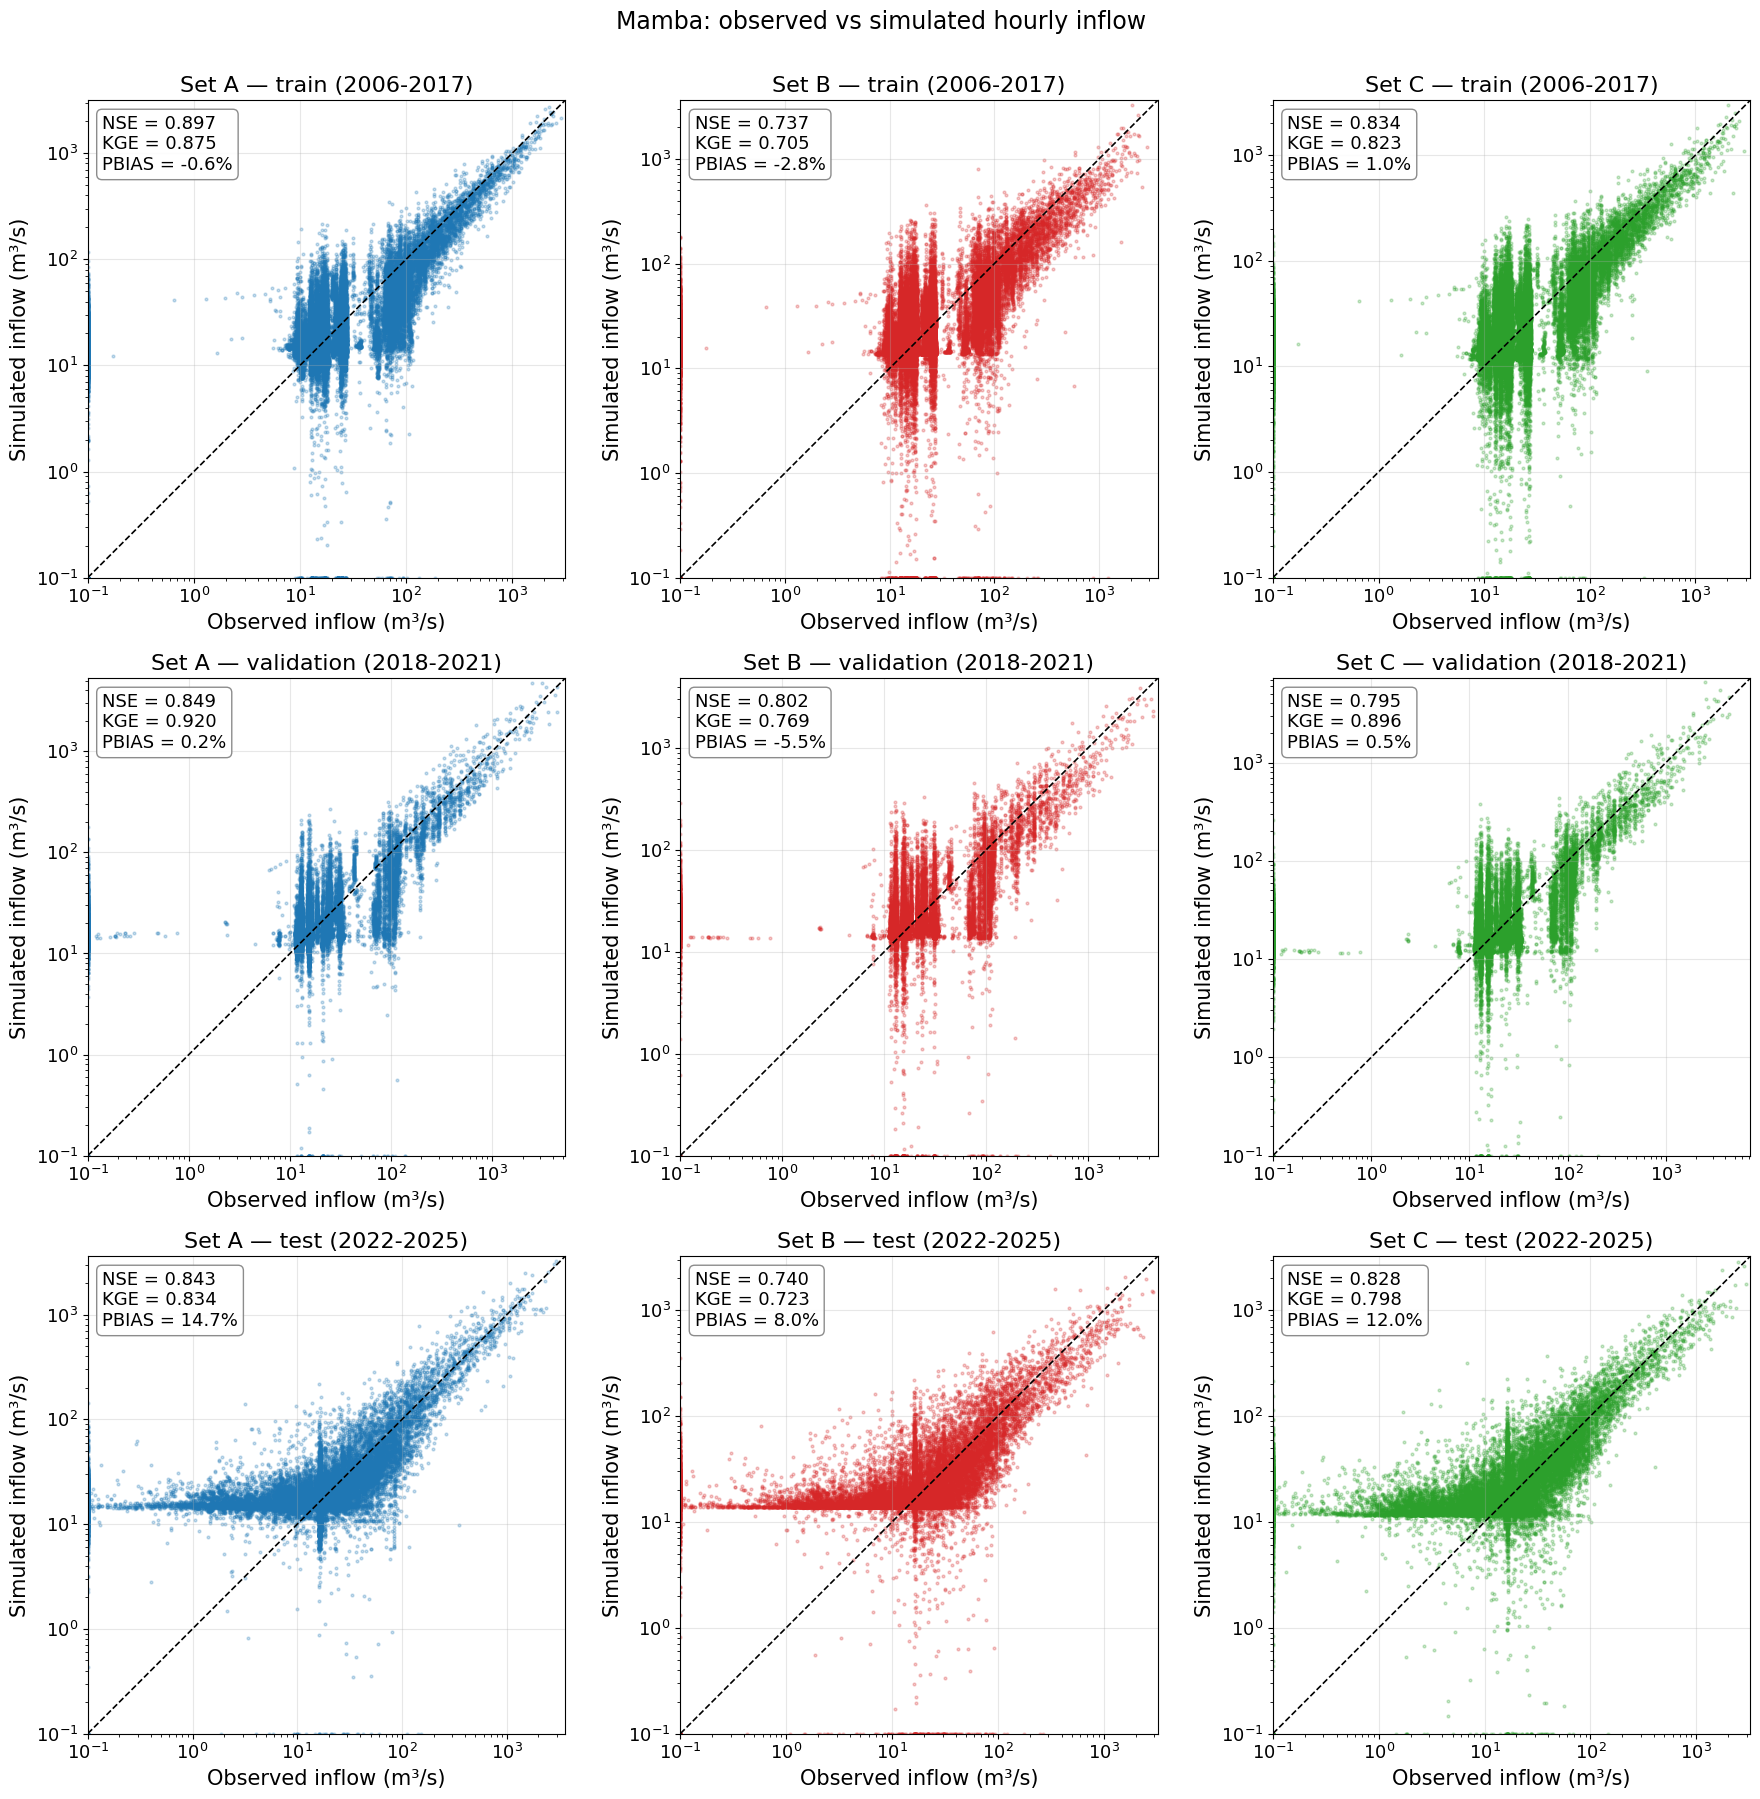

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for i, p in enumerate(PERIODS):
    for j, s in enumerate(SETS):
        df = preds[s][preds[s]["period"] == p]
        common.plot_scatter(df["obs"], df["sim"], title=f"Set {s} — {PERIOD_LABEL[p]}", ax=axes[i, j], color=SET_COLOR[s])
fig.suptitle(f"{NAME}: observed vs simulated hourly inflow", fontsize=17, y=1.0)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_scatter")
plt.show()

## 5. 수문곡선 · 유량지속곡선

### 5.1 테스트 기간(2022–2025) 연도별 수문곡선

각 패널은 한 해의 시간 유입량입니다. 검은 선 = 관측, 색 선 = 입력세트별 예측, 위쪽 막대 = 유역평균 강우(역축).
홍수기(6–9월)의 첨두 크기와 상승·하강 시점, 건기의 저유량 수준을 봅니다.

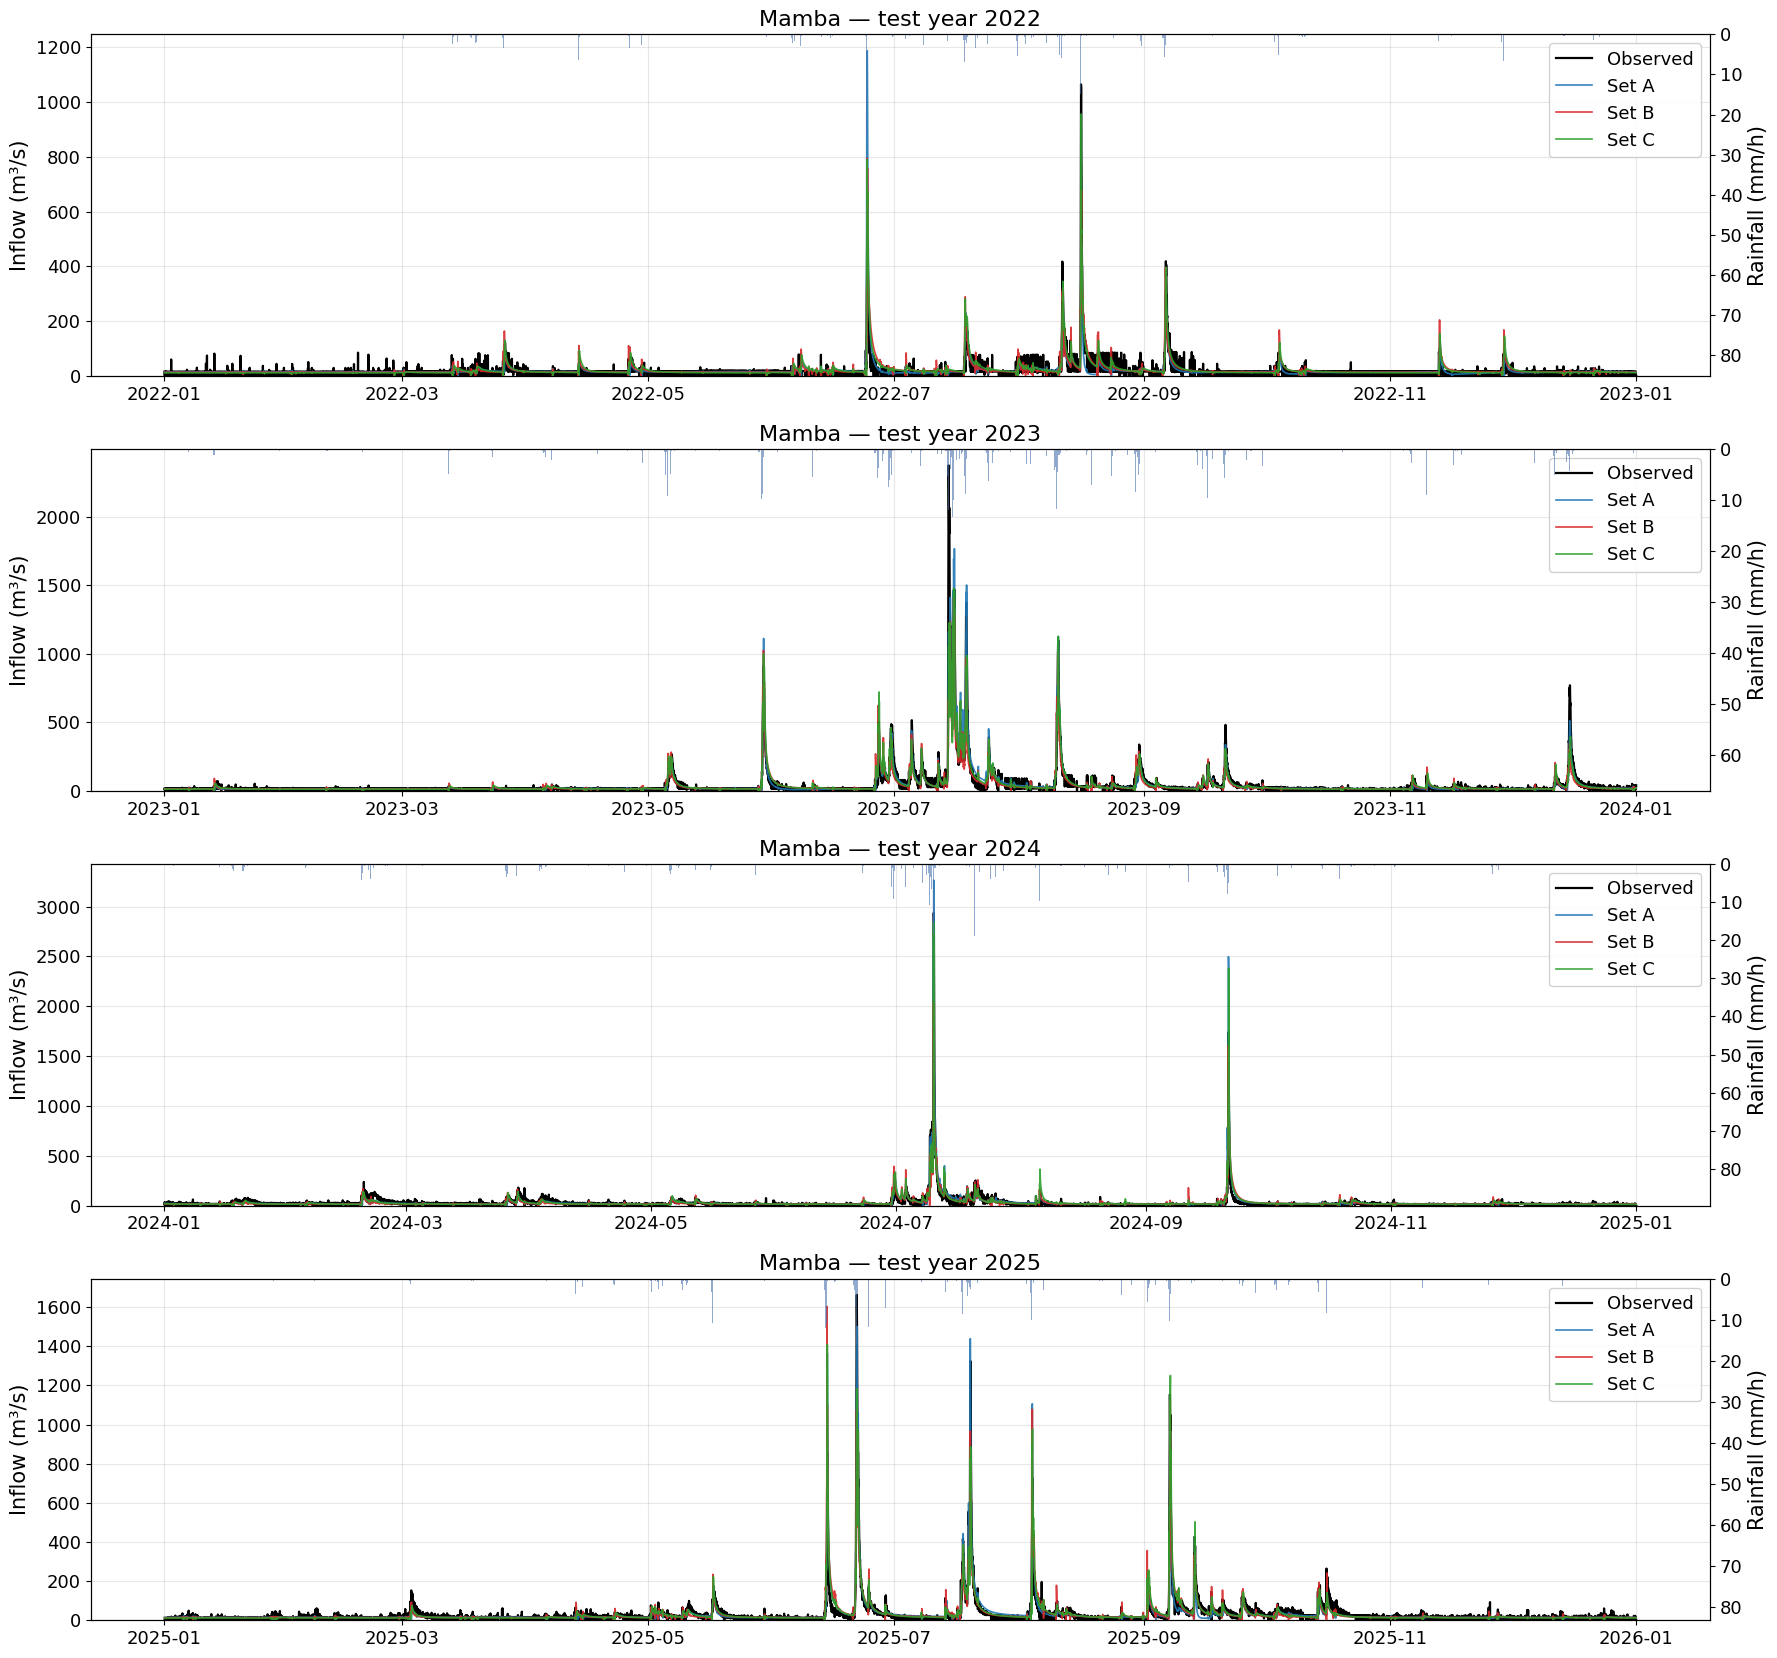

In [9]:
test_years = range(2022, 2026)
fig, axes = plt.subplots(len(test_years), 1, figsize=(18, 4.2 * len(test_years)))
for ax, year in zip(axes, test_years):
    start, end = f"{year}-01-01", f"{year}-12-31 23:00"
    obs = preds["A"].loc[start:end, "obs"]
    common.plot_hydrograph(obs, {f"Set {s}": preds[s].loc[start:end, "sim"] for s in SETS}, rain=rain.loc[start:end],
                           title=f"{NAME} — test year {year}", ax=ax, colors={f"Set {s}": SET_COLOR[s] for s in SETS},
                           styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.2, obs_lw=1.6)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_hydrograph_test")
plt.show()

### 5.2 테스트 기간 최대 홍수사건 3개 확대

관측 첨두가 가장 큰 세 사건을 전후 5일 범위로 확대합니다. 시간 해상도이므로 첨두 **시각**까지 비교할 수 있습니다.

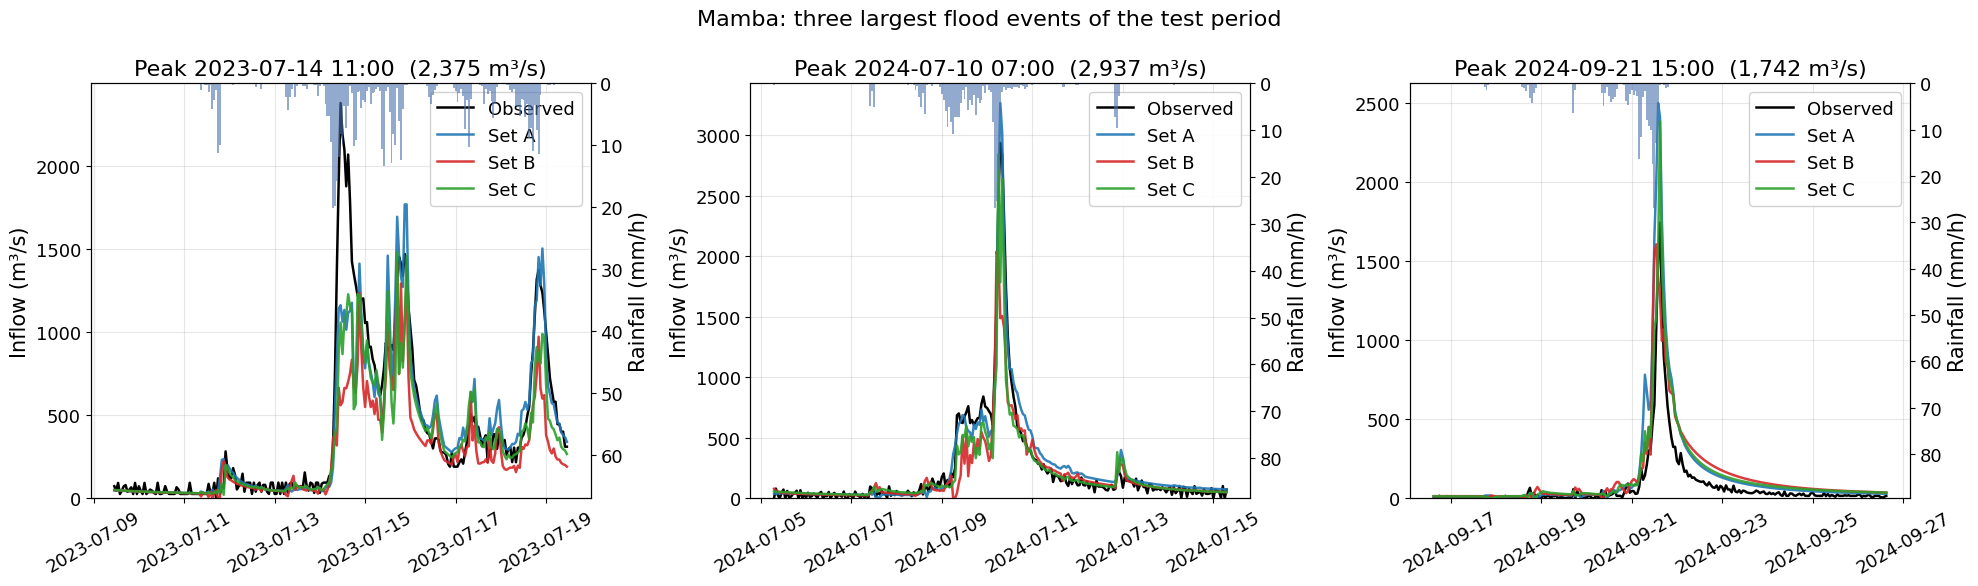

In [10]:
test_obs = preds["A"].loc[preds["A"]["period"] == "test", "obs"]
events = common.detect_events(test_obs, n_events=15)
top3 = sorted(events, key=lambda t: test_obs[t], reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, peak in zip(axes, sorted(top3)):
    start, end = peak - pd.Timedelta(days=5), peak + pd.Timedelta(days=5)
    common.plot_hydrograph(preds["A"]["obs"], {f"Set {s}": preds[s]["sim"] for s in SETS}, rain=rain, start=start, end=end,
                           title=f"Peak {peak:%Y-%m-%d %H:00}  ({test_obs[peak]:,.0f} m³/s)", ax=ax,
                           colors={f"Set {s}": SET_COLOR[s] for s in SETS}, styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.8)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{NAME}: three largest flood events of the test period", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_events_top3")
plt.show()

### 5.3 유량지속곡선 (테스트 기간)

고유량(FHV, 왼쪽 음영)과 저유량(FLV, 오른쪽 음영) 구간에서 관측 곡선과의 간격이 각각 FHV, FLV 지표에 해당합니다.

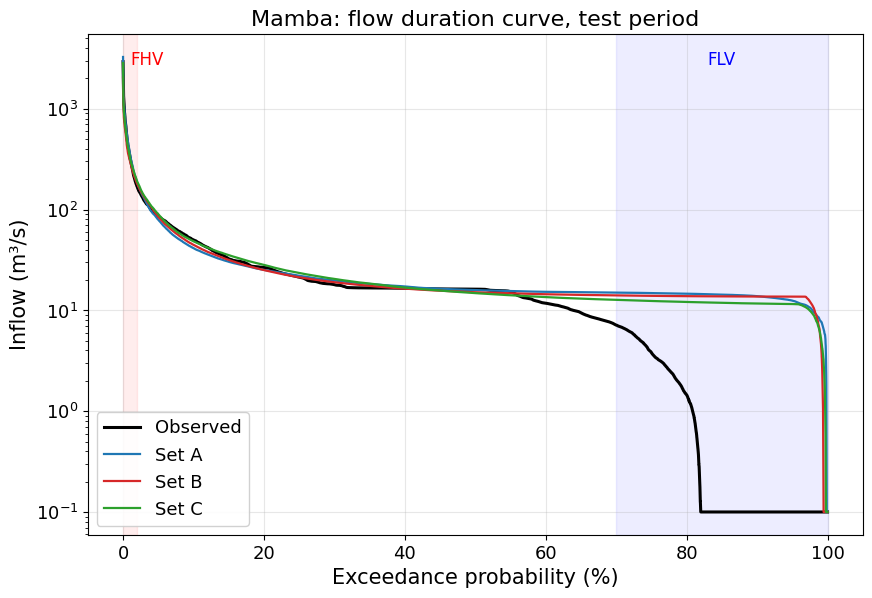

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))
common.plot_fdc(test_obs, {f"Set {s}": preds[s].loc[preds[s]["period"] == "test", "sim"] for s in SETS},
                title=f"{NAME}: flow duration curve, test period", colors={f"Set {s}": SET_COLOR[s] for s in SETS}, ax=ax)
common.save_fig(fig, f"{MODEL}_fdc_test")
plt.show()

### 5.4 연도별 NSE

20년 전체를 연도별로 나눠 본 NSE 입니다. 배경 음영은 학습/검증/테스트 기간. 특정 해의 성능 급락은 보통 그 해의 큰 홍수를 놓쳤음을 뜻합니다.

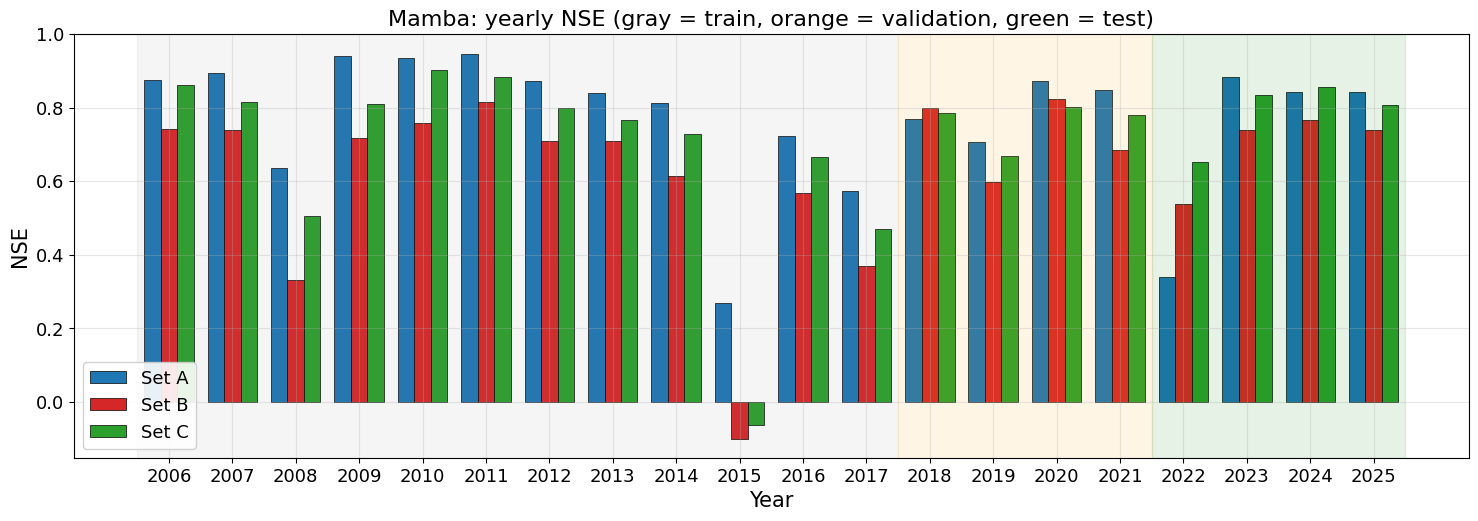

A             B             C       
        NSE    KGE    NSE    KGE    NSE    KGE
year                                          
2006  0.875  0.807  0.741  0.622  0.863  0.788
2007  0.896  0.836  0.739  0.637  0.816  0.751
2008  0.636  0.773  0.331  0.624  0.505  0.716
2009  0.942  0.788  0.718  0.581  0.811  0.694
2010  0.935  0.881  0.757  0.698  0.904  0.893
2011  0.945  0.899  0.815  0.745  0.885  0.814
2012  0.873  0.777  0.711  0.574  0.800  0.721
2013  0.841  0.830  0.710  0.753  0.767  0.833
2014  0.813  0.825  0.615  0.614  0.729  0.760
2015  0.270  0.570 -0.102  0.420 -0.064  0.493
2016  0.722  0.843  0.569  0.754  0.667  0.784
2017  0.573  0.675  0.369  0.632  0.470  0.682
2018  0.768  0.724  0.800  0.859  0.786  0.816
2019  0.708  0.719  0.599  0.641  0.669  0.735
2020  0.873  0.879  0.824  0.705  0.802  0.867
2021  0.849  0.893  0.685  0.610  0.780  0.739
2022  0.340  0.650  0.539  0.639  0.653  0.681
2023  0.882  0.856  0.738  0.648  0.834  0.771
2024  0.844  0.695  0.767  0.754  0.856  0.798
2025  0.842  0.859  0.741  0.780  0.809  0.827

In [12]:
yearly = {s: common.yearly_metrics(preds[s]) for s in SETS}
fig, ax = plt.subplots(figsize=(18, 5.5))
years = yearly["A"].index
w = 0.26
for i, s in enumerate(SETS):
    ax.bar(years + (i - 1) * w, yearly[s]["NSE"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
ax.set_ylim(max(-1, min(0, np.nanmin([yearly[s]["NSE"].min() for s in SETS]) - 0.05)), 1.0)
ax.set_xticks(years)
ax.set_ylabel("NSE")
ax.set_xlabel("Year")
ax.set_title(f"{NAME}: yearly NSE (gray = train, orange = validation, green = test)")
ax.legend(loc="lower left")
common.save_fig(fig, f"{MODEL}_yearly_nse")
plt.show()
display(pd.concat({s: yearly[s][["NSE", "KGE"]] for s in SETS}, axis=1).round(3))

## 6. 홍수 첨두 재현 (테스트 기간 상위 15개 사건)

관측 첨두를 서로 72시간 이상 떨어지도록 골라 독립 사건 15개를 정의하고, 사건마다

- **첨두 크기 오차** = (예측 첨두 − 관측 첨두) / 관측 첨두 × 100 (%) — 예측 첨두는 관측 첨두 ±24 h 안의 최대값
- **첨두 시각 오차** = 예측 첨두 시각 − 관측 첨두 시각 (h, + 는 지연)
- **사건 체적 오차** = 첨두 전 48 h ~ 후 96 h 구간 총량의 상대오차 (%)
- **사건 NSE** = 같은 구간의 NSE

를 계산합니다. 댐 운영에서는 평균적 적합도(NSE)보다 이 값들이 직접적인 관심사입니다.

In [13]:
event_tables = {s: common.load_saved_events(MODEL, s) for s in SETS}
best_set = max(SETS, key=lambda s: summaries[s]["metrics"]["test"]["NSE"])
print(f"테스트 NSE 가 가장 높은 입력세트: {best_set}")
t = event_tables[best_set].copy()
t[t.select_dtypes("number").columns] = t.select_dtypes("number").round(1)
display(t)
display(pd.DataFrame({s: summaries[s]["events_test"] for s in SETS}).round(2))

테스트 NSE 가 가장 높은 입력세트: A


,obs_peak,sim_peak,sim_peak_time,peak_error_pct,timing_error_h,volume_error_pct,event_NSE
obs_peak_time,,,,,,,
2022-08-16 07:00:00,1064.7,486.9,2022-08-16 10:00:00,-54.3,3.0,-51.8,0.6
2023-05-29 14:00:00,915.1,1111.9,2023-05-29 14:00:00,21.5,0.0,7.9,1.0
2023-06-27 02:00:00,506.0,453.9,2023-06-27 03:00:00,-10.3,1.0,13.0,0.7
2023-07-05 08:00:00,515.2,439.2,2023-07-05 06:00:00,-14.8,-2.0,-4.5,0.8
2023-07-14 11:00:00,2375.1,1410.8,2023-07-14 21:00:00,-40.6,10.0,-7.8,0.8
2023-07-18 20:00:00,1372.7,1501.7,2023-07-18 22:00:00,9.4,2.0,24.8,0.9
2023-08-10 16:00:00,1097.7,1126.6,2023-08-10 16:00:00,2.6,0.0,12.7,0.9
2023-12-15 13:00:00,769.9,511.7,2023-12-15 11:00:00,-33.5,-2.0,-26.3,0.8
2024-07-10 07:00:00,2936.9,3265.7,2024-07-10 07:00:00,11.2,0.0,9.5,1.0


,A,B,C
n_events,15.00,15.00,15.00
peak_error_mean_pct,0.67,-8.78,-1.97
peak_error_median_pct,2.63,-20.44,-3.18
peak_abs_error_mean_pct,27.11,31.49,28.39
timing_error_mean_h,0.80,-0.33,1.27
timing_abs_error_mean_h,1.87,2.33,1.80
timing_within_3h_frac,0.93,0.93,0.93
peak_within_20pct_frac,0.47,0.27,0.33
volume_error_mean_pct,11.39,4.08,9.32
event_NSE_median,0.76,0.66,0.79


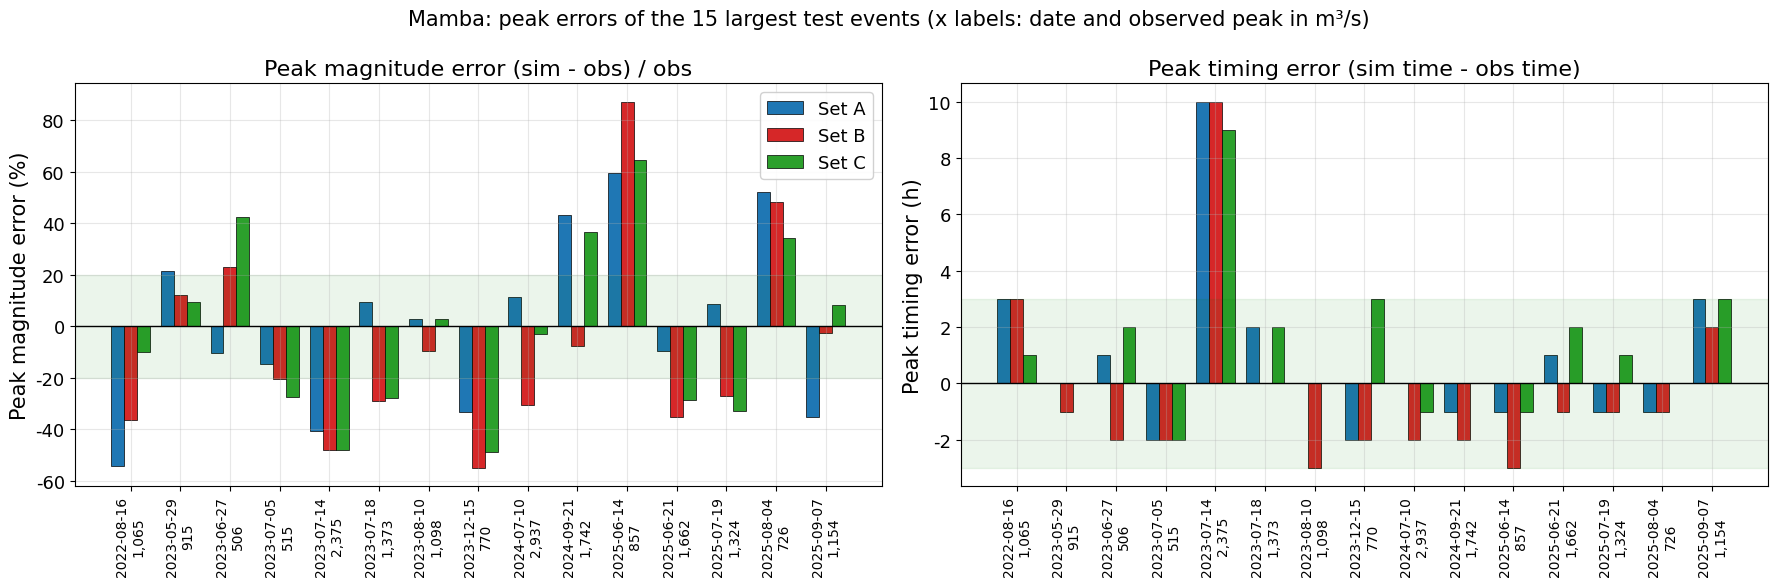

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
table = event_tables["A"]
x = np.arange(len(table))
w = 0.26
for i, s in enumerate(SETS):
    t = event_tables[s].reindex(table.index)
    axes[0].bar(x + (i - 1) * w, t["peak_error_pct"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
    axes[1].bar(x + (i - 1) * w, t["timing_error_h"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
labels = [f"{t:%Y-%m-%d}\n{v:,.0f}" for t, v in zip(table.index, table["obs_peak"])]
for ax, ylabel, title in zip(axes, ["Peak magnitude error (%)", "Peak timing error (h)"],
                             ["Peak magnitude error (sim - obs) / obs", "Peak timing error (sim time - obs time)"]):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=10)
    ax.axhline(0, color="black", lw=1)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].axhspan(-20, 20, color="green", alpha=0.08)
axes[1].axhspan(-3, 3, color="green", alpha=0.08)
axes[0].legend(loc="best")
fig.suptitle(f"{NAME}: peak errors of the 15 largest test events (x labels: date and observed peak in m³/s)", fontsize=15)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_peak_errors")
plt.show()

## 7. 결과 해석

### 7.1 자동 요약 (지표 기반)

아래 글은 `common.narrative_for_run()` 이 지표 값으로부터 규칙적으로 생성한 요약입니다. 모든 모델 노트북에 같은 규칙을 적용하므로
모델 간 서술이 일관됩니다.

In [15]:
for s in SETS:
    display(Markdown(common.narrative_for_run(summaries[s])))

**Mamba / 입력세트 A (basin-average rainfall)**
- 테스트 기간 NSE 0.843, KGE 0.834, RMSE 34.4 m³/s, PBIAS +14.7%.
- 학습 NSE 0.897, 검증 NSE 0.849: 테스트 기간에서 성능이 다소 낮아지지만 큰 과적합 징후는 없습니다.
- 전체 유량을 과대 추정하는 경향(PBIAS +14.7%)이 뚜렷합니다.
- 고유량 구간(FHV +3.8%)은 거의 편향 없이 재현되고, 저유량 구간(FLV -184.7%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 +2.6%, 평균 절대 첨두오차 27.1%, 첨두 시각 오차 평균 +0.8 h (±3 h 이내 93%, 크기 ±20% 이내 47%).
- 학습: 36 epoch (early stopping), 최적 epoch 24, epoch당 평균 34 s, 총 학습시간 20.4 min, 파라미터 32,833개.

**Mamba / 입력세트 B (station rainfall (7 gauges))**
- 테스트 기간 NSE 0.740, KGE 0.723, RMSE 44.2 m³/s, PBIAS +8.0%.
- 학습(0.737)·검증(0.802)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 고유량 구간(FHV -16.5%)은 과소 재현되고, 저유량 구간(FLV -180.3%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -20.4%, 평균 절대 첨두오차 31.5%, 첨두 시각 오차 평균 -0.3 h (±3 h 이내 93%, 크기 ±20% 이내 27%).
- 학습: 45 epoch (early stopping), 최적 epoch 1, epoch당 평균 33 s, 총 학습시간 25.2 min, 파라미터 33,217개.

**Mamba / 입력세트 C (basin-average + station rainfall)**
- 테스트 기간 NSE 0.828, KGE 0.798, RMSE 35.9 m³/s, PBIAS +12.0%.
- 학습(0.834)·검증(0.795)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 전체 유량을 과대 추정하는 경향(PBIAS +12.0%)이 뚜렷합니다.
- 고유량 구간(FHV -7.9%)은 과소 재현되고, 저유량 구간(FLV -180.8%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -3.2%, 평균 절대 첨두오차 28.4%, 첨두 시각 오차 평균 +1.3 h (±3 h 이내 93%, 크기 ±20% 이내 33%).
- 학습: 38 epoch (early stopping), 최적 epoch 4, epoch당 평균 36 s, 총 학습시간 22.9 min, 파라미터 33,281개.

### 7.2 Mamba 의 결과 해석

**요약**: 테스트 NSE 0.84 (A), 0.74 (B), 0.83 (C), KGE 0.72–0.83. LSTM 보다 낮지만 트랜스포머 계열보다는 훨씬 좋고, 첨두 크기 편향은
작다(세트 A 첨두 크기 오차 중앙값 +2.6%).

- **구현 수정**: NeuralHydrology 의 `mamba` 모델은 `InputLayer` 출력([seq, batch, feat])을 전치하지 않고 Mamba 블록에 넣어 **배치 축을
  시간 축으로** 처리하고 있었다(학습 자체가 불가능, 테스트 NSE 0.13). 본 연구에서 이를 수정했고(`modelzoo/mamba.py`), 여기 보고된 값은 수정 후
  결과이다. 수정 전 run 은 `runs/_buggy_mamba_layout/` 에 보관했다.
- **학습 불안정**: 검증 loss 최소가 세트 A 는 24 epoch, **세트 B 는 1 epoch, C 는 4 epoch** 에서 나타났다. 즉 Mamba 는 몇 epoch 만에 검증
  NSE 0.8 에 도달하지만 이후 검증 loss 가 서서히 악화된다(학습 loss 는 계속 감소 → 과적합). 공통 학습률 1e-3 이 Mamba 에는 높은 편이며,
  학습률·드롭아웃 튜닝 여지가 큰 모델이다.
- **총량·저유량**: PBIAS +8 ~ +15% 로 과대 추정하고 저유량 바닥값이 다른 모델보다 높다(FLV 큰 음수는 0 관측값 영향).
- **홍수 첨두**: 세트 A 는 첨두 크기 오차 중앙값 +2.6%, ±20% 이내 47%, 시각 오차 1.9 h 로 **첨두 편향이 가장 작은 모델 중 하나**다. 다만
  평균 절대 오차는 27–31% 로 LSTM 보다 산포가 크다.
- **비용**: 33–36 s/epoch (LSTM 의 4배). 선형 시간 복잡도를 갖지만 hidden 64 의 작은 모델에서는 커널 호출 오버헤드가 지배적이어서 cuDNN LSTM
  보다 느리다. 파라미터 33k.


## 8. 요약

아래 표가 이 노트북의 최종 결과이며, `results/mamba_<set>/summary.json` 으로 저장되어 비교 노트북에서 사용됩니다.

In [16]:
summary_table = pd.DataFrame({
    f"Set {s}": {
        "parameters": summaries[s]["n_parameters"],
        "epochs trained": summaries[s]["epochs_trained"],
        "best epoch": summaries[s]["best_epoch"],
        "early stopped": summaries[s]["early_stopped"],
        "s / epoch": round(summaries[s]["epoch_time_mean_s"], 1),
        "training time (min)": round(summaries[s]["train_time_total_s"] / 60, 1),
        "test NSE": round(summaries[s]["metrics"]["test"]["NSE"], 3),
        "test KGE": round(summaries[s]["metrics"]["test"]["KGE"], 3),
        "test RMSE (m³/s)": round(summaries[s]["metrics"]["test"]["RMSE"], 1),
        "test PBIAS (%)": round(summaries[s]["metrics"]["test"]["PBIAS"], 1),
        "test FHV (%)": round(summaries[s]["metrics"]["test"]["FHV"], 1),
        "peak |error| mean (%)": round(summaries[s]["events_test"]["peak_abs_error_mean_pct"], 1),
        "peak |timing| mean (h)": round(summaries[s]["events_test"]["timing_abs_error_mean_h"], 1),
    } for s in SETS})
display(summary_table)
summary_table.to_csv(common.RESULTS_DIR / f"{MODEL}_summary_table.csv")

,Set A,Set B,Set C
parameters,32833,33217,33281
epochs trained,36,45,38
best epoch,24,1,4
early stopped,True,True,True
s / epoch,33.9,33.4,35.9
training time (min),20.4,25.2,22.9
test NSE,0.843,0.74,0.828
test KGE,0.834,0.723,0.798
test RMSE (m³/s),34.4,44.2,35.9
test PBIAS (%),14.7,8.0,12.0
